## Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from odym import dynamic_stock_model as dsm
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from scipy.optimize import curve_fit


## Read in Data

In [213]:
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\steel production.csv', index_col=0)
df_population = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\Population Data\National Data.xlsx', sheet_name='Population Data', skiprows=0, index_col=0)
df_gdp = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Background Data\usgdp_1931-2025.csv', skiprows=3, index_col=1)
df_floorspace = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\2016_01_10 Levesque FS per capita.xlsx', skiprows=7, index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)

In [214]:
## Get correct years of GDP ##
df_gdp = df_gdp.iloc[1]
df_gdp = df_gdp.iloc[0:94]

In [215]:
## Clean up floorspace DF ##
df_floorspace = df_floorspace.iloc[0]
df_floorspace = pd.DataFrame([df_floorspace])
df_floorspace = df_floorspace.T

In [216]:
df_population

,Population (Thousands),% Change Since Previous Year
Year,,
1900,76094000,NaN
1901,77584000,1.92
1902,79163000,1.99
1903,80632000,1.82
1904,82166000,1.87
...,...,...
2096,366661000,-0.07
2097,366393000,-0.07
2098,366120000,-0.07


In [217]:
df_gdp_SSP2

,SSP1,SSP2,SSP3,SSP4,SSP5,Source
Year,,,,,,
1820,1808.695652,1808.695652,1808.695652,1808.695652,1808.695652,Maddison Project
1821,1837.391304,1837.391304,1837.391304,1837.391304,1837.391304,Maddison Project
1822,1887.826087,1887.826087,1887.826087,1887.826087,1887.826087,Maddison Project
1823,1866.956522,1866.956522,1866.956522,1866.956522,1866.956522,Maddison Project
1824,1917.391304,1917.391304,1917.391304,1917.391304,1917.391304,Maddison Project
...,...,...,...,...,...,...
2080,93330.000000,80449.000000,75829.000000,100906.000000,125749.000000,IIASA_SSP
2085,96883.000000,82781.000000,76764.000000,105514.000000,135088.000000,IIASA_SSP
2090,100716.000000,85163.000000,77731.000000,110455.000000,145269.000000,IIASA_SSP


In [218]:
## Get SSP 2  DF
df_gdp_SSP2.index = df_gdp_SSP2.index.astype(int)  # ensure index is numeric
df_gdp_SSP2 = df_gdp_SSP2.reindex(
    range(df_gdp_SSP2.index.min(), df_gdp_SSP2.index.max() + 1)
)

df_gdp_SSP2 = df_gdp_SSP2.interpolate(method='cubic')

df_gdp_SSP2 = df_gdp_SSP2.iloc[:, [1]]

df_gdp_SSP2 = df_gdp_SSP2.loc[df_gdp_SSP2.index >= 1931]

C:\Users\aorga\AppData\Local\Temp\ipykernel_57432\3951953131.py:7: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_gdp_SSP2 = df_gdp_SSP2.interpolate(method='cubic')


In [ ]:
base_stock = df_floorspace.loc[1931,'Total U.S. floor space (million sq ft)']*0.092903*0.25*68
base_stock = base_stock 

In [220]:
base_stock

np.float64(91138.20140992175)

In [221]:
base_stock_hot_roll = base_stock*(6100/82500)
base_stock_hss = base_stock*(1600/82500)
base_stock_plate = base_stock*(700/82500)

In [222]:
## Forecast Forward ###
## Scale constants ###
hot_roll = (6100/82500)
hss = (1600/82500)
plate = (700/82500)

##GDP linear regression
X_gdp = np.array(df_gdp_SSP2.index).reshape(-1, 1)
y_gdp = df_gdp_SSP2["SSP2"].values
gdp_model = LinearRegression()
gdp_model.fit(X_gdp, y_gdp)

#### Get elasticity approx ####
gdp_elast = gdp_model.coef_[0]


##Population Regression
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

# Fit model
t = df_population.index.values.astype(float)
P = df_population["Population (Thousands)"].values

p0 = [P.max() * 1.1, 0.03, 2000]

params, covariance = curve_fit(logistic, t, P, p0=p0, maxfev=10000)
K, r, t0 = params

### Population elasticity
P_hat = logistic(t, K, r, t0)
pop_elast = r * (1 - P_hat / K) * t
pop_elast_series = pd.Series(pop_elast, index=df_population.index, name="pop_elasticity")


In [223]:
pop_elast_series = pop_elast_series/100
gdp_elast = gdp_elast/1000

In [224]:
pop_elast_series

Year
1900    0.404207
1901    0.402716
1902    0.401194
1903    0.399640
1904    0.398055
          ...   
2096    0.017891
2097    0.017465
2098    0.017048
2099    0.016641
2100    0.016243
Name: pop_elasticity, Length: 201, dtype: float64

In [225]:
### Forcast 
df_steel.index = df_steel.index.astype(int)
df_population.index = df_population.index.astype(int)
df_gdp_SSP2.index = df_gdp_SSP2.index.astype(int)

#build forecast years
forecast_years = np.arange(2024, 2101)

pop_fore = df_population.loc[forecast_years, "Population (Thousands)"]
gdp_fore = df_gdp_SSP2.loc[forecast_years, "SSP2"]
pop_elast_fore = 0.6

hot_roll_steel_fore_vals = hot_roll * (gdp_fore ** gdp_elast)* (pop_fore ** pop_elast_fore) 
hss_steel_fore_vals = hss * (gdp_fore ** gdp_elast)* (pop_fore ** pop_elast_fore) 
plate_steel_fore_vals = plate * (gdp_fore ** gdp_elast)* (pop_fore ** pop_elast_fore) 

df_steel_forecast = pd.DataFrame({
    "hot roll-total": hot_roll_steel_fore_vals*2/1000,
    "HSS-total": hss_steel_fore_vals*2/1000,
    "Plate-total": plate_steel_fore_vals*2/1000,
}, index=forecast_years)


In [226]:
Historic_Years = df_steel.index

In [227]:
df_historic_steel_total = df_steel.iloc[:,1:4]

In [228]:
MFA_Data_Total = pd.concat([df_historic_steel_total,df_steel_forecast],axis=0)

In [229]:
MFA_Data_Total

,hot roll-total,HSS-total,Plate-total
1931,1739.379576,456.616560,200.063957
1932,917.188359,240.777458,105.495278
1933,1557.497255,408.869374,179.143798
1934,1746.754089,458.552494,200.912175
1935,2285.629904,600.016511,262.893832
...,...,...,...
2096,8225.091433,2157.401032,943.862951
2097,8246.264647,2162.954662,946.292664
2098,8267.470847,2168.516943,948.726163
2099,8288.702619,2174.085933,951.162596


In [246]:
## Perform MFA
AvgLifetime = 73.4
InputStdDev = 0.3*AvgLifetime
Historic_Years = df_historic_steel_total.index
Historic_hot_roll = df_historic_steel_total['hot roll-total']
years = MFA_Data_Total.index
hot_roll_total = MFA_Data_Total['hot roll-total']

hot_roll_DSM = dsm.DynamicStockModel(t = np.array(years), i = np.array(hot_roll_total), 
                                  lt = {'Type': 'Normal', 'Mean': np.array([AvgLifetime]), 
                                        'StdDev': np.array([InputStdDev]) })

In [247]:
stock_by_cohort =  hot_roll_DSM.compute_s_c_inflow_driven()
print(stock_by_cohort)
print(stock_by_cohort.shape)


[[1.73863328e+03 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.73850179e+03 9.16794830e+02 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.73834914e+03 9.16725498e+02 1.55682899e+03 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [1.85349451e-02 1.19588997e-02 2.47992616e-02 ... 8.26392360e+03
  0.00000000e+00 0.00000000e+00]
 [1.51181249e-02 9.77362052e-03 2.03076645e-02 ... 8.26329865e+03
  8.28514627e+03 0.00000000e+00]
 [1.23068328e-02 7.97190469e-03 1.65967950e-02 ... 8.26257307e+03
  8.28451971e+03 8.30642770e+03]]
(170, 170)


In [248]:
CheckStr = hot_roll_DSM.dimension_check()
print(CheckStr)

<br><b> Checking dimensions of dynamic stock model DSM.Time vector is present with 170 years.<br>Inflow vector is present with 170 years.<br>Total stock is not present.<br>Stock by cohorts is present with 170 years and 170 cohorts.<br>Total outflow is not present.<br>Outflow by cohorts is not present.<br>Lifetime distribution is present with type Normal.<br>


In [249]:
base_stock_hot_roll

np.float64(6738.703376976033)

In [250]:
S_hot_roll = hot_roll_DSM.compute_stock_total() 
print(S_hot_roll)

[  1738.63327722   2655.2966238    4211.9036329    5957.53316227
   8241.6158992   11441.82964403  14830.71370837  16393.7411616
  19550.82022314  22620.84104774  26804.85838109  30851.11100521
  34860.68432009  38899.19406243  42473.88982123  45532.31180651
  49466.23967139  53658.37386415  57302.99205352  61956.05247836
  67044.88648741  71362.09400195  76529.98513907  80565.03988644
  85971.05107055  91271.87227622  96279.52200131 100086.27780806
 104589.70975477 109299.83050228 113666.11913996 118321.20880276
 123302.89863275 128904.30688902 135012.63844602 140930.48753306
 146427.16871235 152443.58932975 158580.60951162 164495.19786071
 170140.40098683 176086.24593758 183330.25024403 190417.73180666
 195503.74840657 201200.5427003  206984.26976208 213194.03028114
 219528.92870002 224731.41994026 230207.18939024 233844.56269897
 237846.21623917 242219.24212022 246677.30494642 250893.9756766
 255592.63145486 260759.90684394 265586.82042747 270417.61422269
 274779.81262092 279309.596

In [251]:
O_C = hot_roll_DSM.compute_o_c_from_s_c()
print(O_C)

[[ 7.46298780e-01  0.00000000e+00  0.00000000e+00 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.31483380e-01  3.93529143e-01 -0.00000000e+00 ... -0.00000000e+00
  -0.00000000e+00 -0.00000000e+00]
 [ 1.52653398e-01  6.93322076e-02  6.68260291e-01 ... -0.00000000e+00
  -0.00000000e+00 -0.00000000e+00]
 ...
 [ 4.14421959e-03  2.64503876e-03  5.42538284e-03 ...  3.54724380e+00
  -0.00000000e+00 -0.00000000e+00]
 [ 3.41682020e-03  2.18527917e-03  4.49159713e-03 ...  6.24955604e-01
   3.55635351e+00 -0.00000000e+00]
 [ 2.81129211e-03  1.80171583e-03  3.71086951e-03 ...  7.25579129e-01
   6.26560558e-01  3.56548845e+00]]


In [252]:
hot_roll_DSM.__dict__.keys()

dict_keys(['t', 'i', 's', 's_c', 'o', 'o_c', 'lt', 'name', 'pdf', 'sf'])

In [253]:
DS_hot_roll = hot_roll_DSM.compute_stock_change()
print(DS_hot_roll)

[1738.63327722  916.66334658 1556.6070091  1745.62952937 2284.08273693
 3200.21374482 3388.88406435 1563.02745323 3157.07906153 3070.0208246
 4184.01733335 4046.25262412 4009.57331488 4038.50974233 3574.6957588
 3058.42198528 3933.92786488 4192.13419276 3644.61818937 4653.06042484
 5088.83400905 4317.20751454 5167.89113712 4035.05474737 5406.01118412
 5300.82120567 5007.64972509 3806.75580675 4503.43194671 4710.1207475
 4366.28863769 4655.08966279 4981.68983    5601.40825627 6108.331557
 5917.84908704 5496.6811793  6016.4206174  6137.02018187 5914.58834909
 5645.20312611 5945.84495076 7244.00430645 7087.48156263 5086.01659991
 5696.79429373 5783.72706178 6209.76051906 6334.89841889 5202.49124024
 5475.76944998 3637.37330873 4001.6535402  4373.02588105 4458.0628262
 4216.67073018 4698.65577826 5167.27538908 4826.91358353 4830.79379522
 4362.19839823 4529.78380535 4922.00120078 5266.72407953 5354.93589563
 5514.74109526 5775.72894085 5473.13223657 5648.59871756 5762.93068795
 5003.661333

In [254]:
O_hot_roll = hot_roll_DSM.compute_outflow_total()
print(O_hot_roll)

[7.46298780e-01 5.25012523e-01 8.90245897e-01 1.12455963e+00
 1.54716707e+00 2.20227318e+00 2.65470465e+00 2.31360277e+00
 3.36926947e+00 3.87753440e+00 4.97451165e+00 5.70735088e+00
 6.58674912e+00 7.61766267e+00 8.58036120e+00 9.64380372e+00
 1.14368691e+01 1.32156632e+01 1.48835846e+01 1.74201122e+01
 2.00485639e+01 2.24925705e+01 2.59116949e+01 2.89055716e+01
 3.32959079e+01 3.75891323e+01 4.22830519e+01 4.70979192e+01
 5.32129173e+01 5.97816395e+01 6.67996043e+01 7.47892272e+01
 8.35953440e+01 9.33922077e+01 1.04092716e+02 1.15508589e+02
 1.27860284e+02 1.41700420e+02 1.56590781e+02 1.72603276e+02
 1.89914218e+02 2.08856993e+02 2.29729944e+02 2.51634293e+02
 2.74383197e+02 2.99824897e+02 3.26861883e+02 3.55902951e+02
 3.86769533e+02 4.19100418e+02 4.54009832e+02 4.90141909e+02
 5.29247567e+02 5.70579819e+02 6.14060533e+02 6.59692816e+02
 7.07935290e+02 7.58548472e+02 8.11213016e+02 8.66378905e+02
 9.23720802e+02 9.83673495e+02 1.04608890e+03 1.11084592e+03
 1.17782410e+03 1.247108

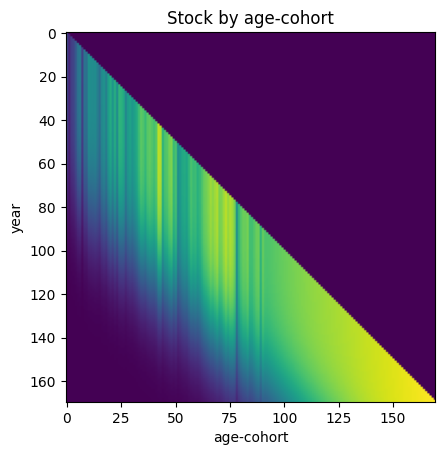

In [ ]:
plt.imshow(hot_roll_DSM.s_c)
plt.xlabel('age-cohort')
plt.ylabel('year')
plt.title('Stock by age-cohort in 2100')
plt.show()

In [256]:
hot_roll_total.loc[1950]

np.float64(4670.480537)

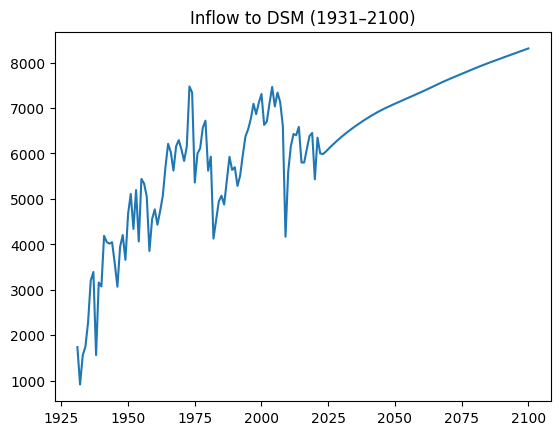

In [257]:
plt.plot(years, hot_roll_total)
plt.title("Inflow to DSM (1931–2100)")
plt.show()

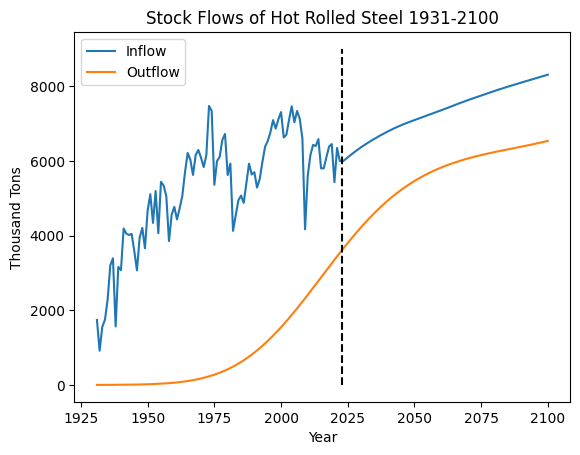

In [271]:
plt1, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.i)
# plt2, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.s)
plt3, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.o)
plt4, = plt.plot([2023,2023],[0,9000], color = 'k', linestyle = '--')
plt.xlabel('Year')
plt.ylabel('Thousand Tons')
plt.title('Stock Flows of Hot Rolled Steel 1931-2100')
plt.legend([plt1,plt3], ['Inflow','Outflow'], loc = 2)
plt.show();

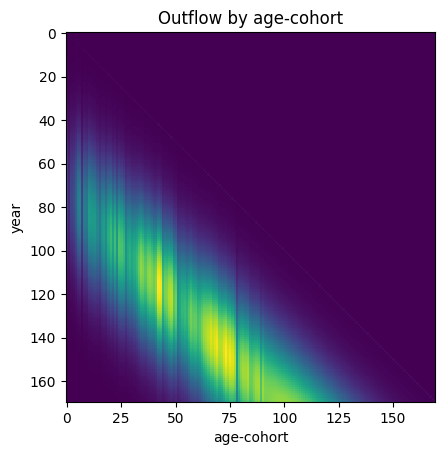

In [258]:
plt.imshow(hot_roll_DSM.o_c,interpolation='nearest')
plt.xlabel('age-cohort')
plt.ylabel('year')
plt.title('Outflow by age-cohort')
plt.show()

In [259]:
# print(hot_roll_DSM.lt)
print(hot_roll_DSM.pdf)
# print(hot_roll_DSM.sf)

None


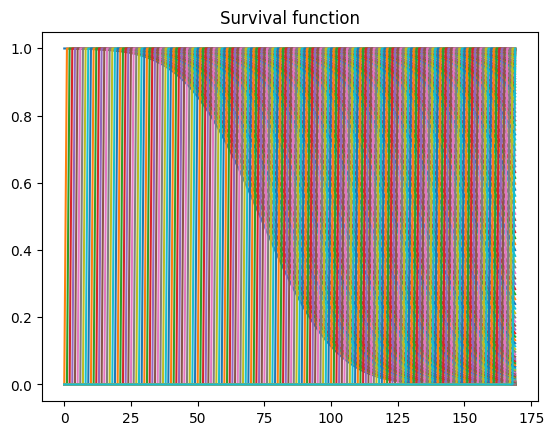

In [269]:
plt.plot(hot_roll_DSM.sf)  # if 1D
plt.title("Survival function")
plt.show()

In [268]:
## Perform MFA HSS
AvgLifetime = 73.4
InputStdDev = 0.3*AvgLifetime
Historic_Years = df_historic_steel_total.index
Historic_hss = df_historic_steel_total['HSS-total']
years = MFA_Data_Total.index
hss_total = MFA_Data_Total['HSS-total']

hss_DSM = dsm.DynamicStockModel(t = np.array(years), i = np.array(hss_total), 
                                  lt = {'Type': 'Normal', 'Mean': np.array([AvgLifetime]), 
                                        'StdDev': np.array([InputStdDev]) })

In [273]:
hss_stock_by_cohort =  hss_DSM.compute_s_c_inflow_driven()
S_hss = hss_DSM.compute_stock_total() 
O_C_hss= hss_DSM.compute_o_c_from_s_c()
O_hss = hss_DSM.compute_outflow_total()
DS_hss  = hss_DSM.compute_stock_change()
Bal_hss = hss_DSM.check_stock_balance()

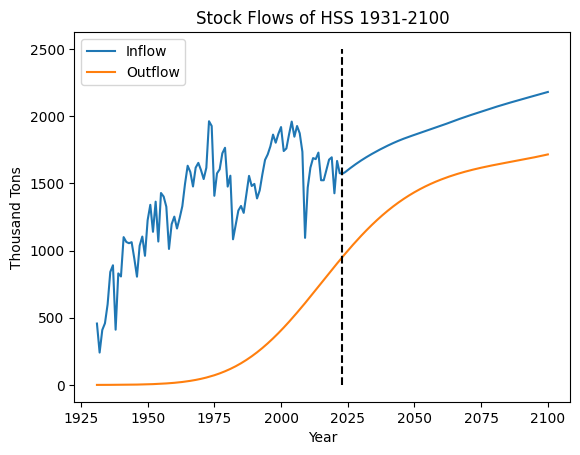

In [275]:
plt1, = plt.plot(hss_DSM.t, hss_DSM.i)
# plt2, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.s)
plt3, = plt.plot(hss_DSM.t, hss_DSM.o)
plt4, = plt.plot([2023,2023],[0,2500], color = 'k', linestyle = '--')
plt.xlabel('Year')
plt.ylabel('Thousand Tons')
plt.title('Stock Flows of HSS 1931-2100')
plt.legend([plt1,plt3], ['Inflow','Outflow'], loc = 2)
plt.show();

In [276]:
## Perform Plate HSS
AvgLifetime = 73.4
InputStdDev = 0.3*AvgLifetime
Historic_Years = df_historic_steel_total.index
Historic_plate = df_historic_steel_total['Plate-total']
years = MFA_Data_Total.index
plate_total = MFA_Data_Total['Plate-total']

plate_DSM = dsm.DynamicStockModel(t = np.array(years), i = np.array(plate_total), 
                                  lt = {'Type': 'Normal', 'Mean': np.array([AvgLifetime]), 
                                        'StdDev': np.array([InputStdDev]) })

In [277]:
plate_stock_by_cohort =  plate_DSM.compute_s_c_inflow_driven()
S_plate = plate_DSM.compute_stock_total() 
O_C_plate= plate_DSM.compute_o_c_from_s_c()
O_plate = plate_DSM.compute_outflow_total()
DS_plate  = plate_DSM.compute_stock_change()
Bal_plate = plate_DSM.check_stock_balance()

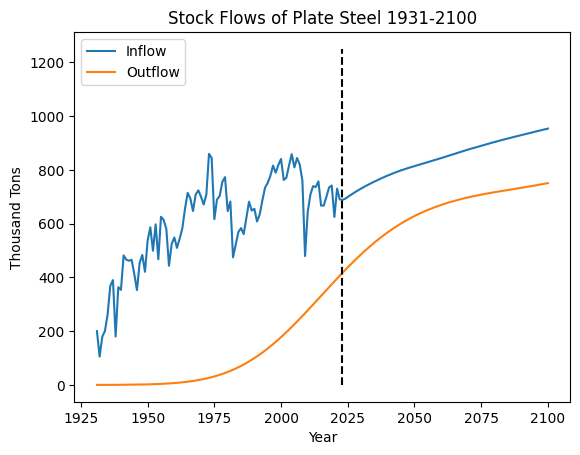

In [279]:
plt1, = plt.plot(plate_DSM.t, plate_DSM.i)
# plt2, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.s)
plt3, = plt.plot(plate_DSM.t, plate_DSM.o)
plt4, = plt.plot([2023,2023],[0,1250], color = 'k', linestyle = '--')
plt.xlabel('Year')
plt.ylabel('Thousand Tons')
plt.title('Stock Flows of Plate Steel 1931-2100')
plt.legend([plt1,plt3], ['Inflow','Outflow'], loc = 2)
plt.show();

Text(0.5, 1.0, 'Estimated Structural Steel Stocks 1931-2100')

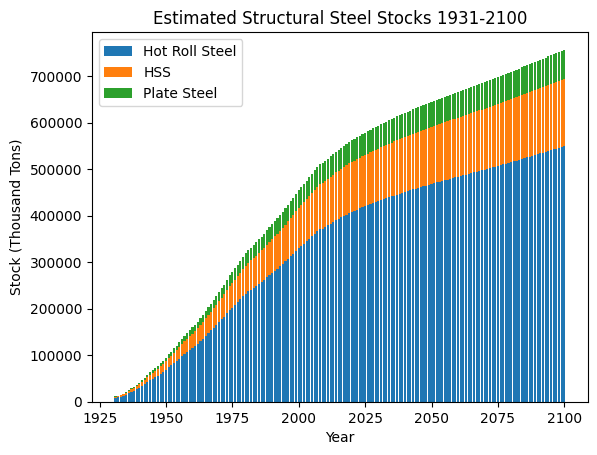

In [281]:
## Create A Stacked Bar Chart of total stock
hot_roll_stock = S_hot_roll + base_stock_hot_roll
HSS_Stock = S_hss + base_stock_hss
Plate_stock = S_plate + base_stock_plate 

plt.bar(plate_DSM.t, hot_roll_stock)
plt.bar(plate_DSM.t, HSS_Stock, bottom=hot_roll_stock)
plt.bar(plate_DSM.t, Plate_stock, bottom=hot_roll_stock+HSS_Stock)
plt.xlabel('Year')
plt.ylabel('Stock (Thousand Tons)')
plt.legend(['Hot Roll Steel', 'HSS', 'Plate Steel'])
plt.title('Estimated Structural Steel Stocks 1931-2100')


In [307]:
total_inflows = hot_roll_DSM.i + hss_DSM.i + plate_DSM.i
total_outflows = hot_roll_DSM.o + hss_DSM.o + plate_DSM.o
years = hot_roll_DSM.t

In [308]:
total_flows = pd.DataFrame({"Total Inflow":total_inflows, 'Total Outflow':total_outflows}, index=years) 

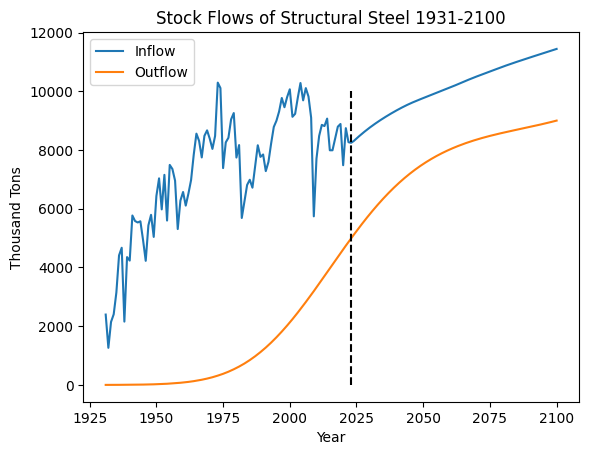

In [295]:
plt1, = plt.plot(total_flows.index, total_flows['Total Inflow'])
# plt2, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.s)
plt3, = plt.plot(total_flows.index, total_flows['Total Outflow'])
plt4, = plt.plot([2023,2023],[0,10000], color = 'k', linestyle = '--')
plt.xlabel('Year')
plt.ylabel('Thousand Tons')
plt.title('Stock Flows of Structural Steel 1931-2100')
plt.legend([plt1,plt3], ['Inflow','Outflow'], loc = 2)
plt.show();

In [294]:
total_flows

,Total Inflow,Total Outflow
1931,2396.060092,1.028054
1932,1263.461095,0.723224
1933,2145.510427,1.226347
1934,2406.218759,1.549123
1935,3148.540247,2.131280
...,...,...
2096,11326.355416,8911.596303
2097,11355.511973,8933.547687
2098,11384.713953,8955.976797
2099,11413.951148,8978.912723


In [312]:
def per_cap_function (df, numerator_cols, denominator_col):
    for num_col in numerator_cols:
        new_col_name = f"{num_col} / capita"
        df[new_col_name] = np.where(df[denominator_col] != 0,
                                    df[num_col] / df[denominator_col],
                                    np.nan)
    return df

total_flows_cap = per_cap_function(total_flows_cap, ['Total Inflow', 'Total Outflow'],
                 'Population (Thousands)')

In [291]:
df_population = df_population.loc[1931:2100].drop(df_population.columns[1], axis=1)

In [310]:
total_flows_cap = pd.concat([total_flows, df_population], axis =1 )

In [311]:
total_flows_cap['Total Inflow'] = total_flows_cap['Total Inflow']*1e6
total_flows_cap['Total Outflow'] = total_flows_cap['Total Outflow']*1e6


In [313]:
total_flows_cap

,Total Inflow,Total Outflow,Population (Thousands),Total Inflow / capita,Total Outflow / capita
1931,2.396060e+09,1.028054e+06,124039648,19.316889,0.008288
1932,1.263461e+09,7.232243e+05,124840471,10.120605,0.005793
1933,2.145510e+09,1.226347e+06,125578763,17.084978,0.009766
1934,2.406219e+09,1.549123e+06,126373773,19.040492,0.012258
1935,3.148540e+09,2.131280e+06,127250232,24.742904,0.016749
...,...,...,...,...,...
2096,1.132636e+10,8.911596e+09,366661000,30.890538,24.304729
2097,1.135551e+10,8.933548e+09,366393000,30.992710,24.382419
2098,1.138471e+10,8.955977e+09,366120000,31.095581,24.461862
2099,1.141395e+10,8.978913e+09,365841000,31.199213,24.543211


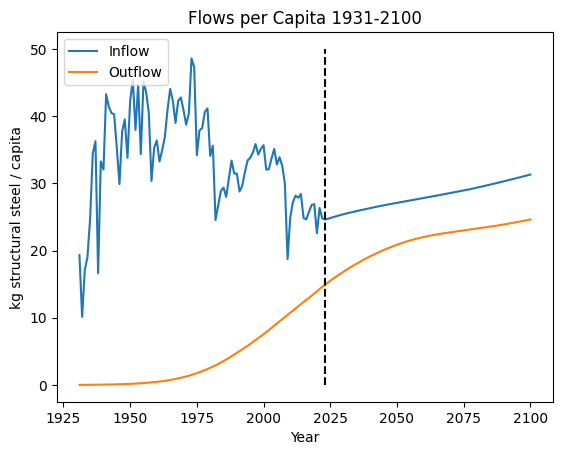

In [315]:
plt1, = plt.plot(total_flows_cap.index, total_flows_cap['Total Inflow / capita'])
# plt2, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.s)
plt3, = plt.plot(total_flows_cap.index, total_flows_cap['Total Outflow / capita'])
plt4, = plt.plot([2023,2023],[0,50], color = 'k', linestyle = '--')
plt.xlabel('Year')
plt.ylabel('kg structural steel / capita')
plt.title('Flows per Capita 1931-2100')
plt.legend([plt1,plt3], ['Inflow','Outflow'], loc = 2)
plt.show();

In [316]:
total_flows_gdp = pd.concat([total_flows, df_gdp_SSP2], axis = 1)

In [317]:
total_flows_gdp

,Total Inflow,Total Outflow,SSP2
1931,2396.060092,1.028054,7711.680000
1932,1263.461095,0.723224,6546.750000
1933,2145.510427,1.226347,6324.900000
1934,2406.218759,1.549123,6852.120000
1935,3148.540247,2.131280,7699.500000
...,...,...,...
2096,11326.355416,8911.596303,88117.822786
2097,11355.511973,8933.547687,88622.369876
2098,11384.713953,8955.976797,89130.805572
2099,11413.951148,8978.912723,89643.294179


In [322]:
total_flows_gdp['Total Inflow'] = total_flows_gdp['Total Inflow']*1e6
total_flows_gdp['Total Outflow'] = total_flows_gdp['Total Outflow']*1e6
total_flows_gdp['SSP2'] = total_flows_gdp['SSP2']*1e6

In [321]:
df_gdp_SSP2.loc[2018]

SSP2    48863.993377
Name: 2018, dtype: float64

In [323]:
def gdp_function (df, numerator_col, denominator_cols):
    for denom in denominator_cols:
        new_col_name = f"$ / {denom}"
        df[new_col_name] = np.where(df[denom] != 0,
                                    df[numerator_col] / df[denom],
                                    np.nan)
    return df

total_flows_gdp = gdp_function(total_flows_gdp, 'SSP2',  ['Total Inflow', 'Total Outflow'])

In [324]:
total_flows_gdp

,Total Inflow,Total Outflow,SSP2,$ / Total Inflow,$ / Total Outflow
1931,2.396060e+09,1.028054e+06,7.711680e+09,3.218484,7501.237715
1932,1.263461e+09,7.232243e+05,6.546750e+09,5.181600,9052.171105
1933,2.145510e+09,1.226347e+06,6.324900e+09,2.947970,5157.513142
1934,2.406219e+09,1.549123e+06,6.852120e+09,2.847671,4423.226027
1935,3.148540e+09,2.131280e+06,7.699500e+09,2.445419,3612.617406
...,...,...,...,...,...
2096,1.132636e+10,8.911596e+09,8.811782e+10,7.779892,9.887995
2097,1.135551e+10,8.933548e+09,8.862237e+10,7.804348,9.920177
2098,1.138471e+10,8.955977e+09,8.913081e+10,7.828989,9.952103
2099,1.141395e+10,8.978913e+09,8.964329e+10,7.853835,9.983758


ValueError: x and y must have same first dimension, but have shapes (170,) and (77,)

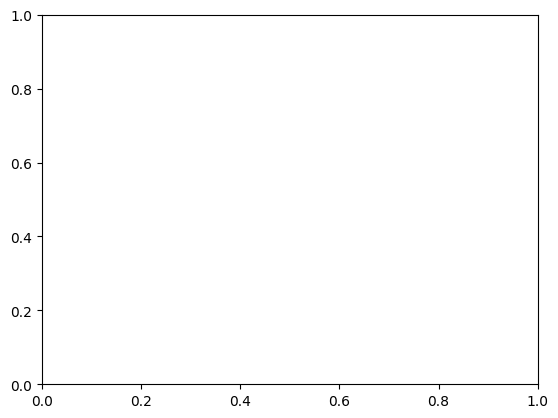

In [328]:
plt1, = plt.plot(total_flows_gdp.index, total_flows_gdp['$ / Total Inflow'].loc[2024:2100])
# plt2, = plt.plot(hot_roll_DSM.t, hot_roll_DSM.s)
plt3, = plt.plot(total_flows_gdp.index, total_flows_gdp['$ / Total Outflow'].loc[2024:2100])
plt4, = plt.plot([2023,2023],[0,50], color = 'k', linestyle = '--')
plt.xlabel('Year')
plt.ylabel('$ / kg structural steel')
plt.title('Dollars per Flow 1931-2100')
plt.legend([plt1,plt3], ['Inflow','Outflow'], loc = 2)
plt.show();